# From Item Response Theory to a Neural Network: Modeling Student Responses in Math Education
## (از نظریه پاسخ به سوال تا شبکه عصبی: مدل سازی پاسخ دانش آموزان در آموزش ریاضی)

**Goal.** Predict whether a student answers a math problem correctly, and study the mathematics behind the models, by building everything **from scratch with NumPy**:

1. **Rasch model (1PL IRT)**: a logistic regression with one ability parameter per student and one difficulty parameter per problem, trained with our own gradient descent and Adam.
2. **Neural network**: student/problem embeddings + a multilayer perceptron, with forward pass, **backpropagation derived by hand** and verified by numerical gradient checking.
3. **Comparison** of both models (log-loss, AUC, calibration, error analysis) on real classroom data (ASSISTments 2009-2010 skill builder).

**Mathematical background.** For student $u$ and problem $i$, with response $y_{ui}\in\{0,1\}$:

$$P(y_{ui}=1)=\sigma(\theta_u-b_i),\qquad \sigma(z)=\frac{1}{1+e^{-z}}$$

where $\theta_u$ is the student's ability and $b_i$ is the problem's difficulty. This is exactly logistic regression on one-hot features, so the Rasch model is both a classical psychometric model and a (very) small neural network.

Regularized negative log-likelihood (our objective):

$$J(\theta,b)=\sum_{(u,i)}\Big[\log\big(1+e^{z_{ui}}\big)-y_{ui}z_{ui}\Big]+\frac{\lambda}{2}\big(\lVert\theta\rVert^2+\lVert b\rVert^2\big),\quad z_{ui}=\theta_u-b_i$$

Gradients (with $p_{ui}=\sigma(z_{ui})$):

$$\frac{\partial J}{\partial\theta_u}=\sum_{i}(p_{ui}-y_{ui})+\lambda\theta_u,\qquad \frac{\partial J}{\partial b_i}=-\sum_{u}(p_{ui}-y_{ui})+\lambda b_i$$

$J$ is convex, so gradient descent converges to the global minimum for a small enough step size.

## Start here: a plain-language guide (no machine-learning background needed)

**The question.** Every answer a student gives tells us a little about two things: how **able** the student is and how **hard** the problem is. Using only *who answered which problem* and *whether the first attempt was correct*, how well can we predict answers that were not observed, and does a neural network predict better than the classical measurement model used in educational psychometrics (the Rasch model)?

**The data.** ASSISTments 2009–2010 *skill builder*: middle-school students practising one math skill at a time until they answer three problems correctly in a row. After cleaning: **271,614 responses, 2,984 students, 10,819 problems, 86 skills, 64.4% correct**. The student × problem table is only 0.84% filled, so prediction means filling in the gaps from the observed pattern.

**The variables.**

| Variable | Meaning | How it is used |
|---|---|---|
| `user_id` | student | becomes the student index *u* |
| `problem_id` | problem | becomes the problem index *i* |
| `correct` | 1 = first attempt correct, 0 = not | the target *y* |
| `order_id` | record id | only to remove duplicated records |
| `skill_name` | math skill | descriptive statistics only |
| θ (theta), b | ability of a student, difficulty of a problem | learned by the Rasch model |
| embeddings | a learned 16-number profile per student and per problem | learned by the neural network |

**The analysis in five steps.**
1. Clean the data and split the responses into train (70%), validation (15%) and test (15%).
2. Build three simple baselines (overall mean, problem mean, student mean).
3. Train the **Rasch model**: P(correct) = σ(θ − b). Only the difference between ability and difficulty matters (θ − b = 0 → 50%, +1 → 73%, +2 → 88%, −1 → 27%, −2 → 12%).
4. Train a **neural network** that combines student and problem profiles.
5. Compare all models on the test set (accuracy, log-loss, AUC, calibration), test whether differences are real (bootstrap), and analyse where each model works better.

**The result in one paragraph.** Both models are far better than the baselines (AUC 0.777 and 0.775 vs 0.703 for the best baseline). The Rasch model is as good as the neural network (slightly better in log-loss, indistinguishable in AUC under the cautious student-level bootstrap), and the neural network learns almost the same ability and difficulty scales (Spearman ≈ 0.97). For first-attempt correctness in these data, a simple and interpretable measurement model is enough.

**How to read this notebook.** Sections 3–4 build the mathematical tools and the Rasch model, with checks that the code is correct. Sections 5–7 load, clean and describe the data and set up baselines. Sections 8–9 train the two models. Sections 10–11 compare them. Sections 12–13 discuss limitations and the educational conclusions. Technical terms are explained in the README glossary.

*Training the models and bootstrap takes a few minutes on a laptop CPU. The raw data file is not part of the repository (see the README).*


In [1]:
# ===================================================
# 1- Required libraries (کتابخانه های مورد نیاز)
# ===================================================
import copy
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse   # used only to verify our implementation (فقط برای راستی آزمایی پیاده سازی)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression   # used only for verification (فقط برای راستی آزمایی)
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [2]:
# ===================================================
# 2- Configuration (تنظیمات پروژه)
# ===================================================
SEED = 42

# Path to the ASSISTments csv file. Leave None to auto-detect it in "." or "data/"
# (مسیر فایل داده؛ اگر None باشد به صورت خودکار در پوشه جاری یا پوشه data جست و جو می شود)
DATA_PATH = None

# Keep only students / problems with enough responses (حذف دانش آموزان و سوالات با پاسخ کم)
MIN_STUDENT_RESPONSES = 10
MIN_PROBLEM_RESPONSES = 10

# Data split proportions (نسبت تقسیم داده ها)
VAL_SIZE = 0.15
TEST_SIZE = 0.15

rng = np.random.default_rng(SEED)

## 3. Mathematical Toolbox (جعبه ابزار ریاضی)
Sigmoid, evaluation metrics and two optimizers (gradient descent and Adam) written from scratch.

In [3]:
# ===================================================
# 3-1- Sigmoid and evaluation metrics (سیگموید و معیارهای ارزیابی)
# ===================================================
def sigmoid(z):
    # Clipping avoids overflow in exp (برش مقادیر برای جلوگیری از سرریز)
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))


def nll_from_logits(z, y):
    # Numerically stable form of -[y log(p) + (1-y) log(1-p)] = log(1+e^z) - y*z
    # (فرم پایدار عددی تابع زیان)
    return np.logaddexp(0.0, z) - y * z


def expected_calibration_error(y, p, n_bins=10):
    # ECE: weighted average gap between predicted probability and observed frequency
    # (میانگین وزنی اختلاف احتمال پیش بینی شده و فراوانی مشاهده شده)
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    ece = 0.0
    for k in range(n_bins):
        mask = idx == k
        if mask.any():
            ece += mask.mean() * abs(y[mask].mean() - p[mask].mean())
    return ece


def evaluate(name, y, p):
    # All metrics of one model in a dictionary (همه معیارهای یک مدل)
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {
        "Model": name,
        "LogLoss": log_loss(y, p),
        "AUC": roc_auc_score(y, p),
        "Accuracy": np.mean((p >= 0.5) == y),
        "Brier": brier_score_loss(y, p),
        "ECE": expected_calibration_error(y, p),
    }

In [4]:
# ===================================================
# 3-2- Optimizers from scratch (بهینه سازها از صفر)
# ===================================================
# Both optimizers update the arrays inside the `params` dictionary in place.
# (هر دو بهینه ساز، آرایه های داخل دیکشنری params را در جا به روز می کنند)
class GradientDescent:
    # x_{t+1} = x_t - lr * grad
    def __init__(self, lr):
        self.lr = lr

    def step(self, params, grads):
        for k in params:
            params[k] -= self.lr * grads[k]


class Adam:
    # Adam: moving averages of the gradient (m) and squared gradient (v) with bias correction
    # (میانگین متحرک گرادیان و مربع گرادیان همراه با تصحیح اریبی)
    def __init__(self, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, 0

    def step(self, params, grads):
        self.t += 1
        for k in params:
            if k not in self.m:
                self.m[k] = np.zeros_like(params[k])
                self.v[k] = np.zeros_like(params[k])
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * grads[k]
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * grads[k] ** 2
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

## 4. Rasch Model (1PL IRT) from Scratch (مدل راش از صفر)
Loss and gradient are fully vectorized: the sums over the responses of each student/problem are computed with `np.bincount`.

**Safe step size for gradient descent.** Each Hessian row of $J$ has absolute sum at most $\tfrac12 d_{\max}+\lambda$, where $d_{\max}$ is the largest number of responses of a single student or problem (since $p(1-p)\le 1/4$). Hence $J$ is $L$-smooth with $L\le \tfrac12 d_{\max}+\lambda$ and the step size $\eta=1/L$ guarantees convergence.

In [5]:
# ===================================================
# 4-1- Rasch loss, gradient and training loop (تابع زیان، گرادیان و حلقه آموزش)
# ===================================================
def rasch_loss_grad(params, u, i, y, lam):
    theta, b = params["theta"], params["b"]
    z = theta[u] - b[i]
    p = sigmoid(z)
    data_loss = np.sum(nll_from_logits(z, y))
    loss = data_loss + 0.5 * lam * (theta @ theta + b @ b)
    r = p - y
    grads = {
        "theta": np.bincount(u, weights=r, minlength=len(theta)) + lam * theta,
        "b": -np.bincount(i, weights=r, minlength=len(b)) + lam * b,
    }
    return loss, data_loss, grads


def fit_rasch(u, i, y, n_users, n_items, lam=1.0, optimizer="adam", n_iter=500, lr=0.05, verbose=False):
    params = {"theta": np.zeros(n_users), "b": np.zeros(n_items)}
    if optimizer == "gd":
        max_degree = max(np.bincount(u).max(), np.bincount(i).max())
        opt = GradientDescent(lr=1.0 / (0.5 * max_degree + lam))   # step size 1/L (گام 1/L)
    else:
        opt = Adam(lr=lr)
    history = []
    for t in range(n_iter):
        loss, data_loss, grads = rasch_loss_grad(params, u, i, y, lam)
        history.append(data_loss / len(y))       # mean training NLL (میانگین زیان آموزش)
        opt.step(params, grads)
        if verbose and (t % 100 == 0):
            print(f"iter {t:4d}  mean train NLL = {history[-1]:.5f}")
    return params, history


def rasch_predict(params, u, i):
    return sigmoid(params["theta"][u] - params["b"][i])

### 4-2. Verifying the implementation (راستی آزمایی پیاده سازی)
Before using real data we check (a) the analytic gradient against numerical differentiation and (b) that the model can **recover known parameters** from simulated data.

In [6]:
# ===================================================
# 4-2-1- Numerical gradient check for the Rasch model (بررسی عددی گرادیان)
# ===================================================
rng_check = np.random.default_rng(0)
n_u, n_i, n_obs = 5, 6, 25
u_c = rng_check.integers(0, n_u, n_obs)
i_c = rng_check.integers(0, n_i, n_obs)
y_c = rng_check.integers(0, 2, n_obs).astype(float)
params_c = {"theta": rng_check.normal(size=n_u), "b": rng_check.normal(size=n_i)}
lam_c = 0.7

_, _, analytic = rasch_loss_grad(params_c, u_c, i_c, y_c, lam_c)

eps = 1e-6
max_rel_err = 0.0
for key in params_c:
    for idx in range(len(params_c[key])):
        original = params_c[key][idx]
        params_c[key][idx] = original + eps
        loss_plus = rasch_loss_grad(params_c, u_c, i_c, y_c, lam_c)[0]
        params_c[key][idx] = original - eps
        loss_minus = rasch_loss_grad(params_c, u_c, i_c, y_c, lam_c)[0]
        params_c[key][idx] = original
        numeric = (loss_plus - loss_minus) / (2 * eps)
        rel_err = abs(numeric - analytic[key][idx]) / max(1e-12, abs(numeric) + abs(analytic[key][idx]))
        max_rel_err = max(max_rel_err, rel_err)

print(f"Max relative error between analytic and numeric gradient: {max_rel_err:.2e}")
print("Gradient check passed" if max_rel_err < 1e-6 else "Gradient check FAILED")

Max relative error between analytic and numeric gradient: 4.82e-09
Gradient check passed


Correlation between true and estimated ability     : 0.976
Correlation between true and estimated difficulty  : 0.993


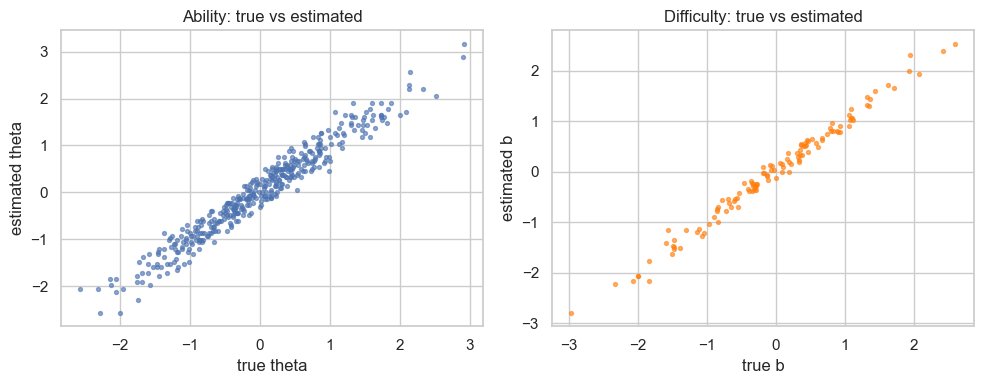

In [7]:
# ===================================================
# 4-2-2- Parameter recovery on simulated data (بازیابی پارامترها روی داده شبیه سازی شده)
# ===================================================
n_u_sim, n_i_sim = 400, 120
theta_true = rng.normal(0, 1, n_u_sim)
b_true = rng.normal(0, 1, n_i_sim)

u_sim = np.repeat(np.arange(n_u_sim), n_i_sim)
i_sim = np.tile(np.arange(n_i_sim), n_u_sim)
y_sim = (rng.random(len(u_sim)) < sigmoid(theta_true[u_sim] - b_true[i_sim])).astype(float)

params_sim, _ = fit_rasch(u_sim, i_sim, y_sim, n_u_sim, n_i_sim, lam=0.1, optimizer="adam", n_iter=600)

corr_theta = np.corrcoef(theta_true, params_sim["theta"])[0, 1]
corr_b = np.corrcoef(b_true, params_sim["b"])[0, 1]
print(f"Correlation between true and estimated ability     : {corr_theta:.3f}")
print(f"Correlation between true and estimated difficulty  : {corr_b:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(theta_true, params_sim["theta"], s=8, alpha=0.6)
axes[0].set_title("Ability: true vs estimated"); axes[0].set_xlabel("true theta"); axes[0].set_ylabel("estimated theta")
axes[1].scatter(b_true, params_sim["b"], s=8, alpha=0.6, color="tab:orange")
axes[1].set_title("Difficulty: true vs estimated"); axes[1].set_xlabel("true b"); axes[1].set_ylabel("estimated b")
plt.tight_layout()
plt.show()

## 5. Data: ASSISTments 2009-2010 Skill Builder (داده ها)
The dataset contains logs of middle-school students solving math problems in the ASSISTments online system. Download the **skill builder** csv file from the ASSISTments data page, and place it next to this notebook or in a `data/` folder (see the README). The file is **not** included in this repository.

Important preprocessing notes:
- In the skill builder file, a record may be **duplicated once per skill** it is tagged with, so we remove duplicates (by `order_id`).
- We keep **one response per (student, problem) pair**.
- The column `correct` is 1 if the student answered correctly on the first attempt (without hints), otherwise 0.

In [8]:
# ===================================================
# 5-1- Loading the dataset (بارگذاری دیتاست)
# ===================================================
def find_data_file():
    if DATA_PATH is not None:
        return DATA_PATH
    for pattern in ["data/*skill_builder*.csv", "*skill_builder*.csv",
                    "data/*assist*.csv", "*assist*.csv", "data/*.csv"]:
        files = sorted(glob.glob(pattern))
        if files:
            return files[0]
    raise FileNotFoundError(
        "ASSISTments csv file not found. Download the 2009-2010 skill builder data, "
        "put it in this folder or in a 'data/' folder, or set DATA_PATH in the configuration cell.")


path = find_data_file()
print("Using data file:", path)

wanted_columns = ["order_id", "user_id", "problem_id", "correct", "skill_name"]
raw = pd.read_csv(path, encoding="ISO-8859-15", low_memory=False,
                  usecols=lambda c: c in wanted_columns)
print("Raw shape:", raw.shape)
print(raw.head())

Using data file: data\skill_builder_data.csv
Raw shape: (525534, 5)
   order_id  user_id  problem_id  correct       skill_name
0  33022537    64525       51424        1  Box and Whisker
1  33022709    64525       51435        1  Box and Whisker
2  35450204    70363       51444        0  Box and Whisker
3  35450295    70363       51395        1  Box and Whisker
4  35450311    70363       51481        0  Box and Whisker


In [9]:
# ===================================================
# 5-2- Cleaning (پاکسازی داده ها)
# ===================================================
df = raw.copy()
print("Rows at start                      :", len(df))

# Remove rows duplicated for multi-skill problems (حذف رکوردهای تکراری چند مهارتی)
if "order_id" in df.columns:
    df = df.drop_duplicates(subset="order_id")
print("After removing duplicate order_id  :", len(df))

# Keep valid rows and binary responses (نگه داشتن سطرهای معتبر و پاسخ های دودویی)
df = df.dropna(subset=["user_id", "problem_id", "correct"])
df = df[df["correct"].isin([0, 1])]
df["correct"] = df["correct"].astype(int)
print("After dropping invalid rows        :", len(df))

# One response per (student, problem) pair: keep the first (یک پاسخ برای هر زوج دانش آموز-سوال)
df = df.drop_duplicates(subset=["user_id", "problem_id"], keep="first")
print("After one response per pair        :", len(df))

# Iteratively remove students/problems with too few responses (حذف تکرار شونده موارد کم پاسخ)
while True:
    n_before = len(df)
    df = df[df["user_id"].map(df["user_id"].value_counts()) >= MIN_STUDENT_RESPONSES]
    df = df[df["problem_id"].map(df["problem_id"].value_counts()) >= MIN_PROBLEM_RESPONSES]
    if len(df) == n_before:
        break
print("After minimum-response filtering   :", len(df))

# Contiguous integer ids (شناسه های عددی پیوسته)
df = df.reset_index(drop=True)
df["u"] = pd.factorize(df["user_id"])[0]
df["i"] = pd.factorize(df["problem_id"])[0]
n_users, n_items = df["u"].nunique(), df["i"].nunique()
print(f"\nFinal data: {len(df)} responses, {n_users} students, {n_items} problems")
print(f"Density of the student x problem matrix: {len(df) / (n_users * n_items):.4%}")

Rows at start                      : 525534
After removing duplicate order_id  : 346860
After dropping invalid rows        : 346860
After one response per pair        : 342081
After minimum-response filtering   : 271614

Final data: 271614 responses, 2984 students, 10819 problems
Density of the student x problem matrix: 0.8413%


## 6. Exploratory Data Analysis (تحلیل اکتشافی داده ها)

Overall proportion of correct responses: 0.6438


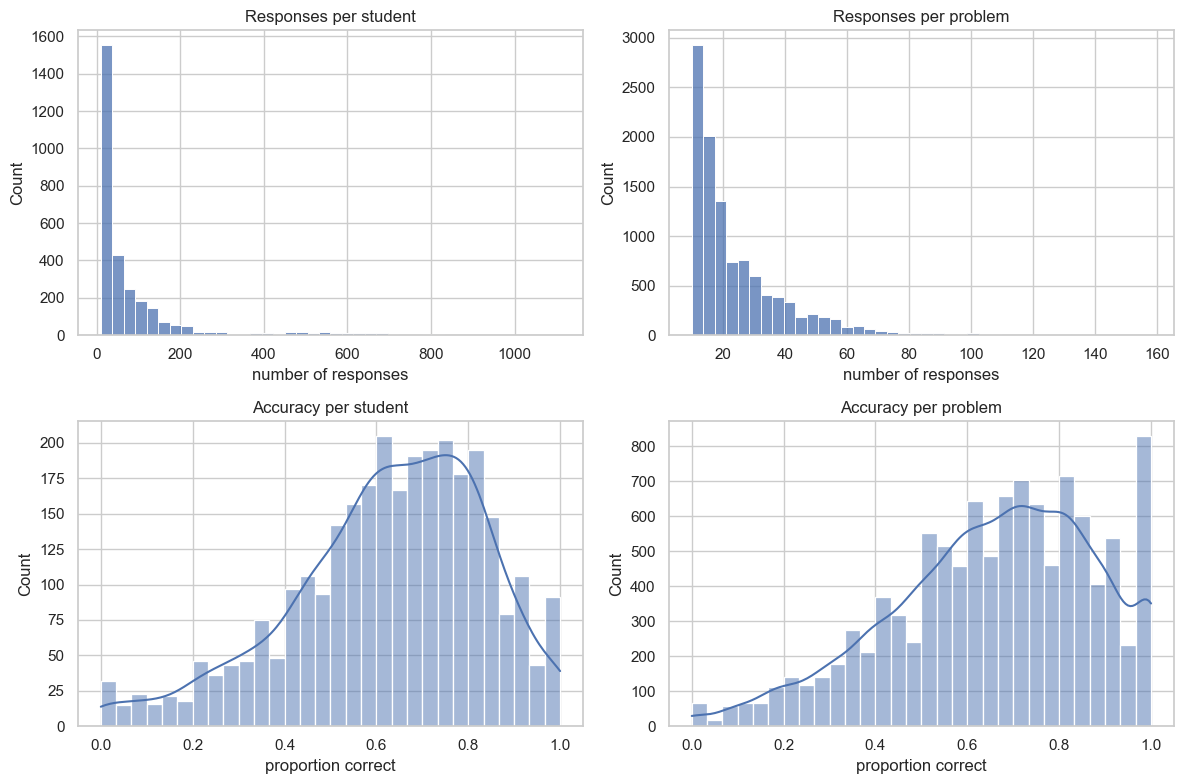

,students,problems
count,2984.00,10819.00
mean,91.02,25.11
std,148.47,18.42
min,10.00,10.00
25%,17.00,13.00
50%,35.00,19.00
75%,94.00,31.00
max,1109.00,158.00


In [10]:
# ===================================================
# 6-1- Target distribution and activity (توزیع متغیر هدف و میزان فعالیت)
# ===================================================
print("Overall proportion of correct responses:", round(df["correct"].mean(), 4))

student_counts = df.groupby("u").size()
problem_counts = df.groupby("i").size()
student_acc = df.groupby("u")["correct"].mean()
problem_acc = df.groupby("i")["correct"].mean()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(student_counts, bins=40, ax=axes[0, 0]); axes[0, 0].set_title("Responses per student"); axes[0, 0].set_xlabel("number of responses")
sns.histplot(problem_counts, bins=40, ax=axes[0, 1]); axes[0, 1].set_title("Responses per problem"); axes[0, 1].set_xlabel("number of responses")
sns.histplot(student_acc, bins=30, kde=True, ax=axes[1, 0]); axes[1, 0].set_title("Accuracy per student"); axes[1, 0].set_xlabel("proportion correct")
sns.histplot(problem_acc, bins=30, kde=True, ax=axes[1, 1]); axes[1, 1].set_title("Accuracy per problem"); axes[1, 1].set_xlabel("proportion correct")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"students": student_counts.describe(), "problems": problem_counts.describe()}).round(2))

Number of skills: 86


,responses,accuracy
skill_name,,
Equation Solving Two or Fewer Steps,22250,0.678
Conversion of Fraction Decimals Percents,17545,0.632
Addition and Subtraction Integers,12038,0.596
Addition and Subtraction Fractions,10667,0.683
Proportion,7096,0.651
Equation Solving More Than Two Steps,6952,0.757
Subtraction Whole Numbers,6661,0.640
Pythagorean Theorem,6117,0.627
Ordering Positive Decimals,5796,0.727


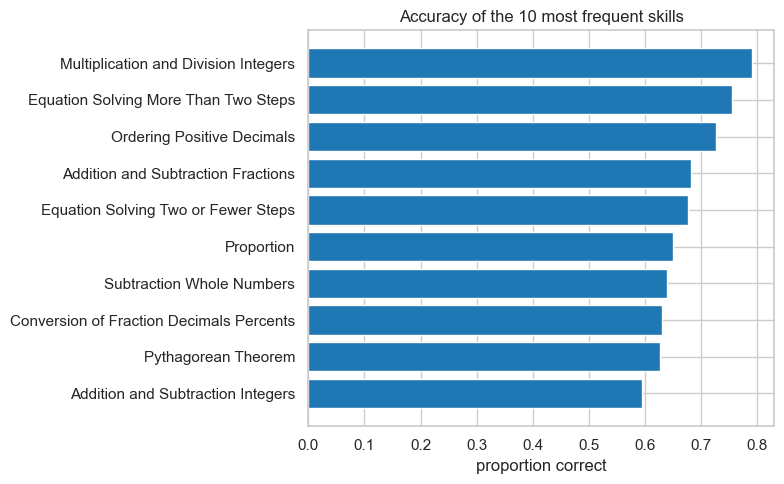

In [11]:
# ===================================================
# 6-2- Skills (مهارت ها)
# ===================================================
if "skill_name" in df.columns:
    skill_summary = (df.groupby("skill_name")["correct"]
                       .agg(responses="size", accuracy="mean")
                       .sort_values("responses", ascending=False))
    print("Number of skills:", len(skill_summary))
    display(skill_summary.head(10).round(3))

    top = skill_summary.head(10).sort_values("accuracy")
    plt.figure(figsize=(8, 5))
    plt.barh(top.index.astype(str), top["accuracy"], color="tab:blue")
    plt.xlabel("proportion correct")
    plt.title("Accuracy of the 10 most frequent skills")
    plt.tight_layout()
    plt.show()
else:
    print("skill_name column not available in this file.")

## 7. Train / Validation / Test Split and Baselines (تقسیم داده و مدل های پایه)
We predict **held-out responses** of known students on known problems. The split is random over responses (70% / 15% / 15%), and validation/test rows whose student or problem never appears in the training set are dropped (so every prediction uses learned parameters).

In [12]:
# ===================================================
# 7-1- Splitting the data (تقسیم داده ها)
# ===================================================
all_idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(all_idx, test_size=VAL_SIZE + TEST_SIZE, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE), random_state=SEED)

u_all, i_all, y_all = df["u"].to_numpy(), df["i"].to_numpy(), df["correct"].to_numpy().astype(float)

seen_u = np.zeros(n_users, dtype=bool); seen_u[u_all[train_idx]] = True
seen_i = np.zeros(n_items, dtype=bool); seen_i[i_all[train_idx]] = True

def keep_seen(idx):
    mask = seen_u[u_all[idx]] & seen_i[i_all[idx]]
    return idx[mask], int((~mask).sum())

val_idx, dropped_val = keep_seen(val_idx)
test_idx, dropped_test = keep_seen(test_idx)

u_tr, i_tr, y_tr = u_all[train_idx], i_all[train_idx], y_all[train_idx]
u_va, i_va, y_va = u_all[val_idx], i_all[val_idx], y_all[val_idx]
u_te, i_te, y_te = u_all[test_idx], i_all[test_idx], y_all[test_idx]

print(f"Train: {len(y_tr)}   Validation: {len(y_va)} (dropped {dropped_val})   Test: {len(y_te)} (dropped {dropped_test})")
print("Correct rate  train/val/test:", round(y_tr.mean(), 3), round(y_va.mean(), 3), round(y_te.mean(), 3))

Train: 190129   Validation: 40742 (dropped 0)   Test: 40743 (dropped 0)
Correct rate  train/val/test: 0.645 0.64 0.644


In [13]:
# ===================================================
# 7-2- Baselines (مدل های پایه)
# ===================================================
results = []   # list of metric dictionaries (لیست معیارهای مدل ها)
test_probs = {}   # predictions on the test set, used later for plots (پیش بینی ها روی داده تست)

def smoothed_mean_predict(idx_train, y_train, idx_query, n_groups, prior, k=5):
    # Mean of y per group shrunk towards the global mean (میانگین هر گروه با انقباض به میانگین کل)
    s = np.bincount(idx_train, weights=y_train, minlength=n_groups)
    c = np.bincount(idx_train, minlength=n_groups)
    return ((s + k * prior) / (c + k))[idx_query]

global_mean = y_tr.mean()
test_probs["Global mean"] = np.full(len(y_te), global_mean)
test_probs["Problem mean"] = smoothed_mean_predict(i_tr, y_tr, i_te, n_items, global_mean)
test_probs["Student mean"] = smoothed_mean_predict(u_tr, y_tr, u_te, n_users, global_mean)

for name in ["Global mean", "Problem mean", "Student mean"]:
    results.append(evaluate(name, y_te, test_probs[name]))

pd.DataFrame(results).round(4)

,Model,LogLoss,AUC,Accuracy,Brier,ECE
0,Global mean,0.6511,0.5000,0.6440,0.2293,0.0007
1,Problem mean,0.5883,0.7031,0.6865,0.2018,0.0063
2,Student mean,0.6001,0.6784,0.6839,0.2061,0.0071


## 8. Training the Rasch Model (آموزش مدل راش)

In [14]:
# ===================================================
# 8-1- Tuning the regularization strength lambda on the validation set (تنظیم لاندا)
# ===================================================
lambda_grid = [0.1, 0.3, 1.0, 3.0, 10.0]
rasch_tuning = []

for lam in lambda_grid:
    t0 = time.time()
    params_l, _ = fit_rasch(u_tr, i_tr, y_tr, n_users, n_items, lam=lam, optimizer="adam", n_iter=500, lr=0.05)
    p_val = np.clip(rasch_predict(params_l, u_va, i_va), 1e-6, 1 - 1e-6)
    rasch_tuning.append({"lambda": lam, "val LogLoss": log_loss(y_va, p_val),
                         "val AUC": roc_auc_score(y_va, p_val), "seconds": round(time.time() - t0, 1)})

rasch_tuning = pd.DataFrame(rasch_tuning)
display(rasch_tuning.round(4))
best_lambda = rasch_tuning.loc[rasch_tuning["val LogLoss"].idxmin(), "lambda"]
print("Best lambda:", best_lambda)

,lambda,val LogLoss,val AUC,seconds
0,0.1,0.5467,0.7728,8.7
1,0.3,0.5394,0.7739,8.1
2,1.0,0.5371,0.7734,7.0
3,3.0,0.5482,0.7669,5.7
4,10.0,0.5761,0.7435,6.2


Best lambda: 1.0


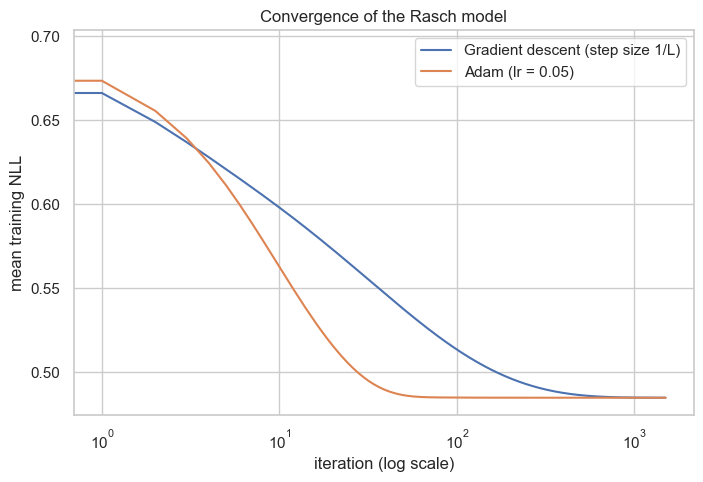

Gradient descent  validation LogLoss = 0.5371   AUC = 0.7734
Adam              validation LogLoss = 0.5371   AUC = 0.7734


In [15]:
# ===================================================
# 8-2- Gradient descent vs Adam: convergence (مقایسه همگرایی گرادیان کاهشی و آدام)
# ===================================================
params_gd, hist_gd = fit_rasch(u_tr, i_tr, y_tr, n_users, n_items, lam=best_lambda, optimizer="gd", n_iter=1500)
params_adam, hist_adam = fit_rasch(u_tr, i_tr, y_tr, n_users, n_items, lam=best_lambda, optimizer="adam", n_iter=1500, lr=0.05)

plt.figure(figsize=(8, 5))
plt.plot(hist_gd, label="Gradient descent (step size 1/L)")
plt.plot(hist_adam, label="Adam (lr = 0.05)")
plt.xscale("log")
plt.xlabel("iteration (log scale)")
plt.ylabel("mean training NLL")
plt.title("Convergence of the Rasch model")
plt.legend()
plt.show()

for name, prm in [("Gradient descent", params_gd), ("Adam", params_adam)]:
    p_val = np.clip(rasch_predict(prm, u_va, i_va), 1e-6, 1 - 1e-6)
    print(f"{name:17s} validation LogLoss = {log_loss(y_va, p_val):.4f}   AUC = {roc_auc_score(y_va, p_val):.4f}")

In [16]:
# ===================================================
# 8-3- Verification against scikit-learn (راستی آزمایی با scikit-learn)
# ===================================================
# The Rasch objective is exactly an L2-regularized logistic regression without intercept on
# one-hot features [student | -problem] with C = 1 / lambda.
# (هدف راش دقیقا رگرسیون لجستیک با جریمه L2 و بدون عرض از مبدا روی ویژگی های وان هات است)
n_tr = len(y_tr)
X_tr = sparse.hstack([
    sparse.csr_matrix((np.ones(n_tr), (np.arange(n_tr), u_tr)), shape=(n_tr, n_users)),
    sparse.csr_matrix((-np.ones(n_tr), (np.arange(n_tr), i_tr)), shape=(n_tr, n_items))]).tocsr()

n_te = len(y_te)
X_te = sparse.hstack([
    sparse.csr_matrix((np.ones(n_te), (np.arange(n_te), u_te)), shape=(n_te, n_users)),
    sparse.csr_matrix((-np.ones(n_te), (np.arange(n_te), i_te)), shape=(n_te, n_items))]).tocsr()

sk_model = LogisticRegression(C=1.0 / best_lambda, fit_intercept=False, solver="lbfgs", tol=1e-8, max_iter=2000)
sk_model.fit(X_tr, y_tr.astype(int))
p_sklearn = sk_model.predict_proba(X_te)[:, 1]
p_ours = rasch_predict(params_adam, u_te, i_te)

print("Max |p_ours - p_sklearn|  :", np.abs(p_ours - p_sklearn).max().round(5))
print("Mean |p_ours - p_sklearn| :", np.abs(p_ours - p_sklearn).mean().round(6))
print("Test AUC ours / sklearn   :", round(roc_auc_score(y_te, p_ours), 4), "/", round(roc_auc_score(y_te, p_sklearn), 4))

Max |p_ours - p_sklearn|  : 0.00104
Mean |p_ours - p_sklearn| : 1e-05
Test AUC ours / sklearn   : 0.7769 / 0.7769


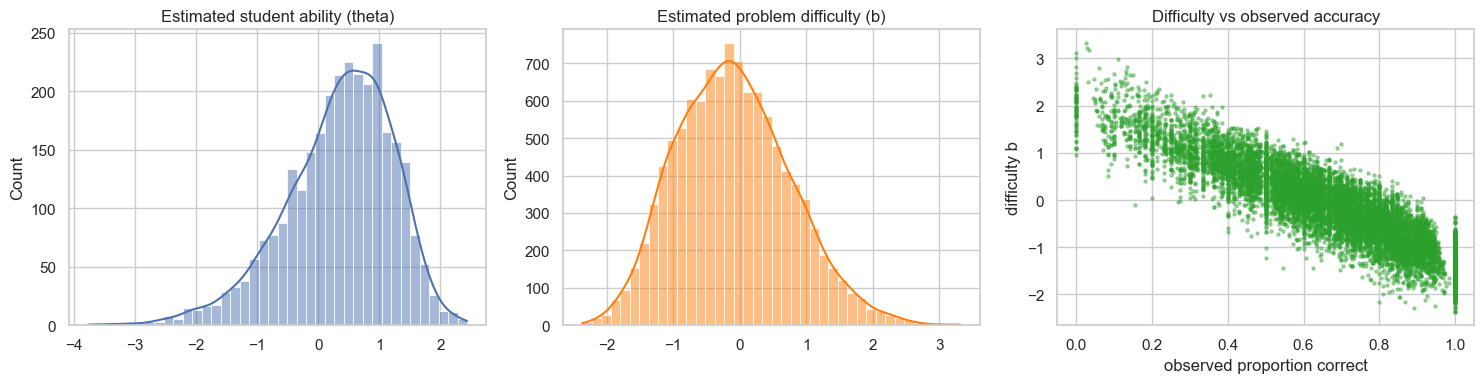

,Model,LogLoss,AUC,Accuracy,Brier,ECE
0,Global mean,0.6511,0.5000,0.6440,0.2293,0.0007
1,Problem mean,0.5883,0.7031,0.6865,0.2018,0.0063
2,Student mean,0.6001,0.6784,0.6839,0.2061,0.0071
3,Rasch (IRT),0.5325,0.7769,0.7361,0.1781,0.0092


In [17]:
# ===================================================
# 8-4- Final Rasch model: evaluation on the test set (ارزیابی نهایی روی داده تست)
# ===================================================
rasch_params = params_adam
test_probs["Rasch (IRT)"] = rasch_predict(rasch_params, u_te, i_te)
results.append(evaluate("Rasch (IRT)", y_te, test_probs["Rasch (IRT)"]))

# Estimated parameters (پارامترهای برآورد شده)
theta_hat, b_hat = rasch_params["theta"], rasch_params["b"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(theta_hat, bins=40, kde=True, ax=axes[0]); axes[0].set_title("Estimated student ability (theta)")
sns.histplot(b_hat, bins=40, kde=True, ax=axes[1], color="tab:orange"); axes[1].set_title("Estimated problem difficulty (b)")
axes[2].scatter(problem_acc.reindex(range(n_items)).to_numpy(), b_hat, s=5, alpha=0.4, color="tab:green")
axes[2].set_xlabel("observed proportion correct"); axes[2].set_ylabel("difficulty b"); axes[2].set_title("Difficulty vs observed accuracy")
plt.tight_layout()
plt.show()

pd.DataFrame(results).round(4)

## 9. Neural Network from Scratch (شبکه عصبی از صفر)
**Architecture.** Each student $u$ and problem $i$ has a learnable embedding $e_u, v_i\in\mathbb{R}^d$. The input is
$x=[e_u,\,v_i,\,e_u\odot v_i]$, followed by two ReLU layers and a sigmoid output:

$$z_1=xW_1+c_1,\;a_1=\mathrm{ReLU}(z_1),\quad z_2=a_1W_2+c_2,\;a_2=\mathrm{ReLU}(z_2),\quad s=a_2W_3+c_3,\quad p=\sigma(s)$$

The loss is the mean binary cross-entropy over a mini-batch of size $B$.

**Backpropagation** (with $\delta_s=(p-y)/B$ and $\odot$ the elementwise product):

$$\frac{\partial L}{\partial W_3}=a_2^\top\delta_s,\quad \delta_{z_2}=(\delta_sW_3^\top)\odot\mathbb{1}[z_2>0],\quad \frac{\partial L}{\partial W_2}=a_1^\top\delta_{z_2},\quad \delta_{z_1}=(\delta_{z_2}W_2^\top)\odot\mathbb{1}[z_1>0],\quad \frac{\partial L}{\partial W_1}=x^\top\delta_{z_1}$$

and $\delta_x=\delta_{z_1}W_1^\top$ is split into three blocks $(\delta_{x}^{(u)},\delta_{x}^{(i)},\delta_{x}^{(\odot)})$, so that

$$\frac{\partial L}{\partial e_u}=\sum_{\text{batch rows of }u}\big(\delta_x^{(u)}+\delta_x^{(\odot)}\odot v_i\big),\qquad \frac{\partial L}{\partial v_i}=\sum_{\text{batch rows of }i}\big(\delta_x^{(i)}+\delta_x^{(\odot)}\odot e_u\big)$$

(the bias gradients are the column sums of the corresponding $\delta$). Weight decay (L2) is added to the gradients of embeddings and weight matrices, and the number of epochs is chosen by early stopping on the validation set.

In [18]:
# ===================================================
# 9-1- Network: parameters, forward pass, backward pass (پارامترها، گذر رو به جلو و رو به عقب)
# ===================================================
WEIGHT_KEYS = ["Eu", "Ei", "W1", "W2", "W3"]   # parameters that receive weight decay (پارامترهای دارای weight decay)


def init_nn_params(n_users, n_items, emb_dim=16, hidden=(64, 32), init_bias=0.0, seed=0):
    r = np.random.default_rng(seed)
    d, h1, h2 = emb_dim, hidden[0], hidden[1]
    return {
        "Eu": r.normal(0, 0.1, (n_users, d)),
        "Ei": r.normal(0, 0.1, (n_items, d)),
        "W1": r.normal(0, np.sqrt(2.0 / (3 * d)), (3 * d, h1)), "b1": np.zeros(h1),   # He initialization
        "W2": r.normal(0, np.sqrt(2.0 / h1), (h1, h2)),         "b2": np.zeros(h2),
        "W3": r.normal(0, np.sqrt(2.0 / h2), (h2, 1)),          "b3": np.array([init_bias]),
    }


def nn_forward(P, u, i):
    eu, ei = P["Eu"][u], P["Ei"][i]
    x = np.concatenate([eu, ei, eu * ei], axis=1)
    z1 = x @ P["W1"] + P["b1"]; a1 = np.maximum(z1, 0)
    z2 = a1 @ P["W2"] + P["b2"]; a2 = np.maximum(z2, 0)
    logit = (a2 @ P["W3"] + P["b3"]).ravel()
    return logit, (u, i, eu, ei, x, z1, a1, z2, a2)


def scatter_add_rows(n_rows, idx, values):
    # Sum the rows of `values` that share the same index: out[k] = sum of values[idx == k]
    # (جمع سطرهایی که اندیس یکسان دارند؛ مشتق عملیات انتخاب سطر از ماتریس امبدینگ)
    out = np.empty((n_rows, values.shape[1]))
    for k in range(values.shape[1]):
        out[:, k] = np.bincount(idx, weights=values[:, k], minlength=n_rows)
    return out


def nn_backward(P, cache, y, logit):
    u, i, eu, ei, x, z1, a1, z2, a2 = cache
    B, d = len(y), eu.shape[1]
    d_s = ((sigmoid(logit) - y) / B).reshape(-1, 1)          # dL/ds
    G = {}
    G["W3"] = a2.T @ d_s;           G["b3"] = d_s.sum(axis=0)
    d_z2 = (d_s @ P["W3"].T) * (z2 > 0)
    G["W2"] = a1.T @ d_z2;          G["b2"] = d_z2.sum(axis=0)
    d_z1 = (d_z2 @ P["W2"].T) * (z1 > 0)
    G["W1"] = x.T @ d_z1;           G["b1"] = d_z1.sum(axis=0)
    d_x = d_z1 @ P["W1"].T
    dx_u, dx_i, dx_p = d_x[:, :d], d_x[:, d:2 * d], d_x[:, 2 * d:]
    G["Eu"] = scatter_add_rows(P["Eu"].shape[0], u, dx_u + dx_p * ei)
    G["Ei"] = scatter_add_rows(P["Ei"].shape[0], i, dx_i + dx_p * eu)
    return G


def nn_loss(P, u, i, y):
    logit, _ = nn_forward(P, u, i)
    return np.mean(nll_from_logits(logit, y))


def nn_predict(P, u, i, chunk=200000):
    out = np.empty(len(u))
    for s in range(0, len(u), chunk):
        logit, _ = nn_forward(P, u[s:s + chunk], i[s:s + chunk])
        out[s:s + chunk] = sigmoid(logit)
    return out

In [19]:
# ===================================================
# 9-2- Numerical gradient check of backpropagation (بررسی عددی گرادیان پس انتشار)
# ===================================================
r = np.random.default_rng(1)
P_chk = init_nn_params(n_users=6, n_items=7, emb_dim=3, hidden=(5, 4), seed=1)
for k in ["b1", "b2", "b3"]:                       # non-zero biases make the check stricter
    P_chk[k] = r.normal(0, 0.3, P_chk[k].shape)
u_chk, i_chk = r.integers(0, 6, 12), r.integers(0, 7, 12)
y_chk = r.integers(0, 2, 12).astype(float)

logit_chk, cache_chk = nn_forward(P_chk, u_chk, i_chk)
G_chk = nn_backward(P_chk, cache_chk, y_chk, logit_chk)

eps = 1e-6
max_rel_err = 0.0
for key in P_chk:
    flat = P_chk[key].ravel()
    for pos in range(len(flat)):
        original = flat[pos]
        flat[pos] = original + eps; loss_plus = nn_loss(P_chk, u_chk, i_chk, y_chk)
        flat[pos] = original - eps; loss_minus = nn_loss(P_chk, u_chk, i_chk, y_chk)
        flat[pos] = original
        numeric = (loss_plus - loss_minus) / (2 * eps)
        analytic = G_chk[key].ravel()[pos]
        rel_err = abs(numeric - analytic) / max(1e-12, abs(numeric) + abs(analytic))
        max_rel_err = max(max_rel_err, rel_err)

print(f"Max relative error over ALL parameters: {max_rel_err:.2e}")
print("Backpropagation check passed" if max_rel_err < 1e-5 else "Backpropagation check FAILED")

Max relative error over ALL parameters: 2.75e-06
Backpropagation check passed


In [20]:
# ===================================================
# 9-3- Training loop with mini-batches and early stopping (حلقه آموزش با mini-batch و توقف زودهنگام)
# ===================================================
def train_nn(u, i, y, u_val, i_val, y_val, n_users, n_items, emb_dim=16, hidden=(64, 32),
             lr=3e-3, weight_decay=1e-4, batch_size=1024, max_epochs=40, patience=4, seed=0, verbose=True):
    P = init_nn_params(n_users, n_items, emb_dim, hidden, init_bias=np.log(y.mean() / (1 - y.mean())), seed=seed)
    opt = Adam(lr=lr)
    shuffler = np.random.default_rng(seed)
    best_loss, best_P, best_epoch, wait = np.inf, None, 0, 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(1, max_epochs + 1):
        perm = shuffler.permutation(len(y))
        batch_losses = []
        for s in range(0, len(y), batch_size):
            b_idx = perm[s:s + batch_size]
            logit, cache = nn_forward(P, u[b_idx], i[b_idx])
            batch_losses.append(np.mean(nll_from_logits(logit, y[b_idx])))
            G = nn_backward(P, cache, y[b_idx], logit)
            for k in WEIGHT_KEYS:                    # L2 weight decay (جریمه L2)
                G[k] += weight_decay * P[k]
            opt.step(P, G)

        val_loss = nn_loss(P, u_val, i_val, y_val)
        history["train_loss"].append(np.mean(batch_losses)); history["val_loss"].append(val_loss)
        if verbose:
            print(f"epoch {epoch:2d}  train loss {history['train_loss'][-1]:.4f}  val loss {val_loss:.4f}")

        if val_loss < best_loss - 1e-5:
            best_loss, best_P, best_epoch, wait = val_loss, copy.deepcopy(P), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                if verbose:
                    print(f"Early stopping at epoch {epoch}; best epoch = {best_epoch}")
                break
    return best_P, history, best_loss, best_epoch

In [21]:
# ===================================================
# 9-4- Tuning weight decay on the validation set (تنظیم weight decay)
# ===================================================
wd_grid = [1e-5, 1e-4, 1e-3]
nn_tuning, nn_models = [], {}

for wd in wd_grid:
    t0 = time.time()
    P_wd, hist_wd, best_val, best_ep = train_nn(u_tr, i_tr, y_tr, u_va, i_va, y_va, n_users, n_items,
                                                weight_decay=wd, seed=SEED, verbose=False)
    p_val = np.clip(nn_predict(P_wd, u_va, i_va), 1e-6, 1 - 1e-6)
    nn_models[wd] = (P_wd, hist_wd)
    nn_tuning.append({"weight_decay": wd, "best epoch": best_ep, "val LogLoss": best_val,
                      "val AUC": roc_auc_score(y_va, p_val), "seconds": round(time.time() - t0, 1)})

nn_tuning = pd.DataFrame(nn_tuning)
display(nn_tuning.round({"best epoch": 0, "val LogLoss": 4, "val AUC": 4}))
best_wd = nn_tuning.loc[nn_tuning["val LogLoss"].idxmin(), "weight_decay"]
print("Best weight decay:", best_wd)

,weight_decay,best epoch,val LogLoss,val AUC,seconds
0,0.00001,2,0.5429,0.7701,15.5
1,0.00010,3,0.5394,0.7718,18.2
2,0.00100,10,0.5407,0.7697,33.9


Best weight decay: 0.0001


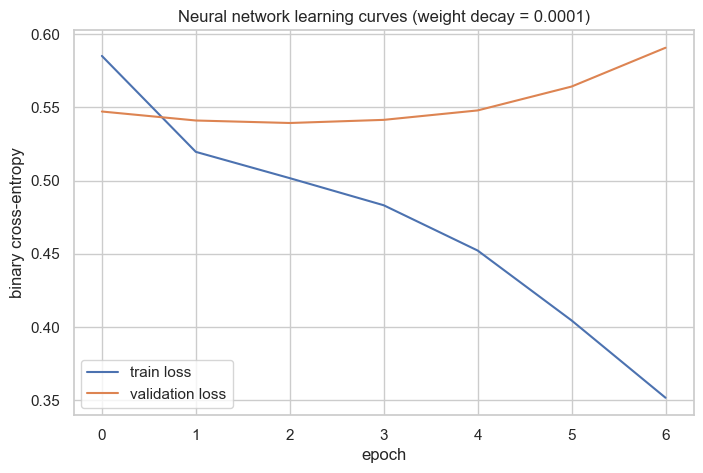

,Model,LogLoss,AUC,Accuracy,Brier,ECE
0,Global mean,0.6511,0.5000,0.6440,0.2293,0.0007
1,Problem mean,0.5883,0.7031,0.6865,0.2018,0.0063
2,Student mean,0.6001,0.6784,0.6839,0.2061,0.0071
3,Rasch (IRT),0.5325,0.7769,0.7361,0.1781,0.0092
4,Neural network,0.5346,0.7752,0.7342,0.1791,0.0137


In [22]:
# ===================================================
# 9-5- Learning curves and test evaluation (منحنی یادگیری و ارزیابی روی داده تست)
# ===================================================
nn_params, nn_hist = nn_models[best_wd]

plt.figure(figsize=(8, 5))
plt.plot(nn_hist["train_loss"], label="train loss")
plt.plot(nn_hist["val_loss"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.title(f"Neural network learning curves (weight decay = {best_wd})")
plt.legend()
plt.show()

test_probs["Neural network"] = nn_predict(nn_params, u_te, i_te)
results.append(evaluate("Neural network", y_te, test_probs["Neural network"]))
pd.DataFrame(results).round(4)

## 10. Final Comparison of the Models (مقایسه نهایی مدل ها)

In [23]:
# ===================================================
# 10-1- Results table (جدول نتایج)
# ===================================================
res_df = pd.DataFrame(results).sort_values(by="AUC", ascending=False).reset_index(drop=True)
res_df

,Model,LogLoss,AUC,Accuracy,Brier,ECE
0,Rasch (IRT),0.532539,0.776940,0.736126,0.178094,0.009179
1,Neural network,0.534624,0.775175,0.734237,0.179109,0.013684
2,Problem mean,0.588267,0.703084,0.686523,0.201780,0.006295
3,Student mean,0.600143,0.678444,0.683872,0.206089,0.007066
4,Global mean,0.651105,0.500000,0.643963,0.229275,0.000688


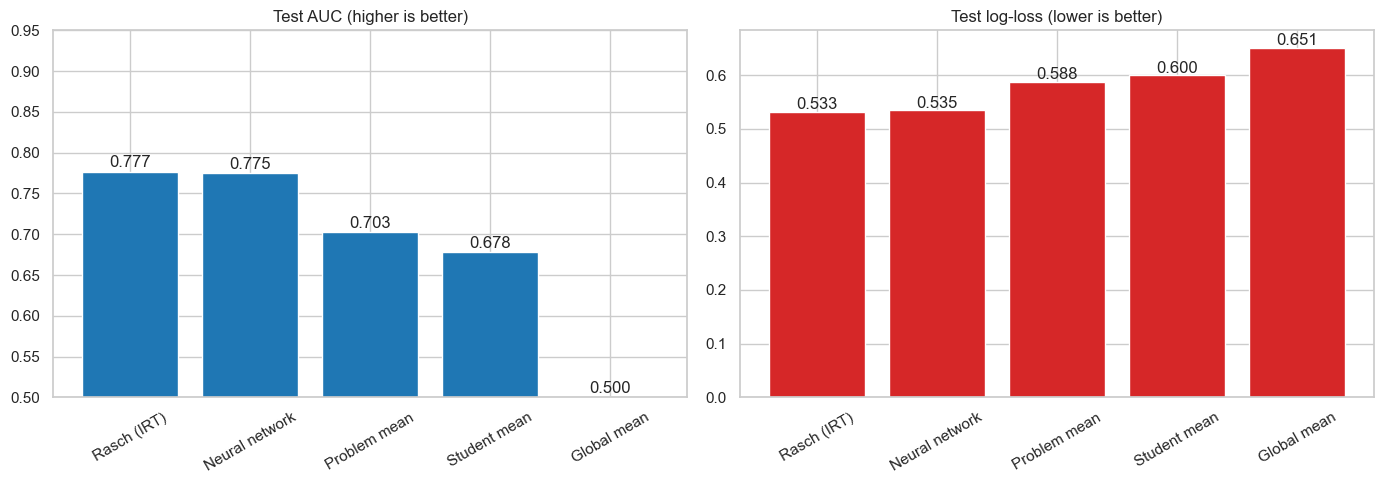

In [24]:
# ===================================================
# 10-2- Metric bar charts (نمودار میله ای معیارها)
# ===================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = res_df["Model"].tolist()

axes[0].bar(order, res_df["AUC"], color="tab:blue")
axes[0].set_ylim(0.5, max(0.95, res_df["AUC"].max() + 0.02)); axes[0].set_title("Test AUC (higher is better)")
for k, v in enumerate(res_df["AUC"]):
    axes[0].text(k, v + 0.005, f"{v:.3f}", ha="center")

axes[1].bar(order, res_df["LogLoss"], color="tab:red")
axes[1].set_title("Test log-loss (lower is better)")
for k, v in enumerate(res_df["LogLoss"]):
    axes[1].text(k, v + 0.005, f"{v:.3f}", ha="center")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

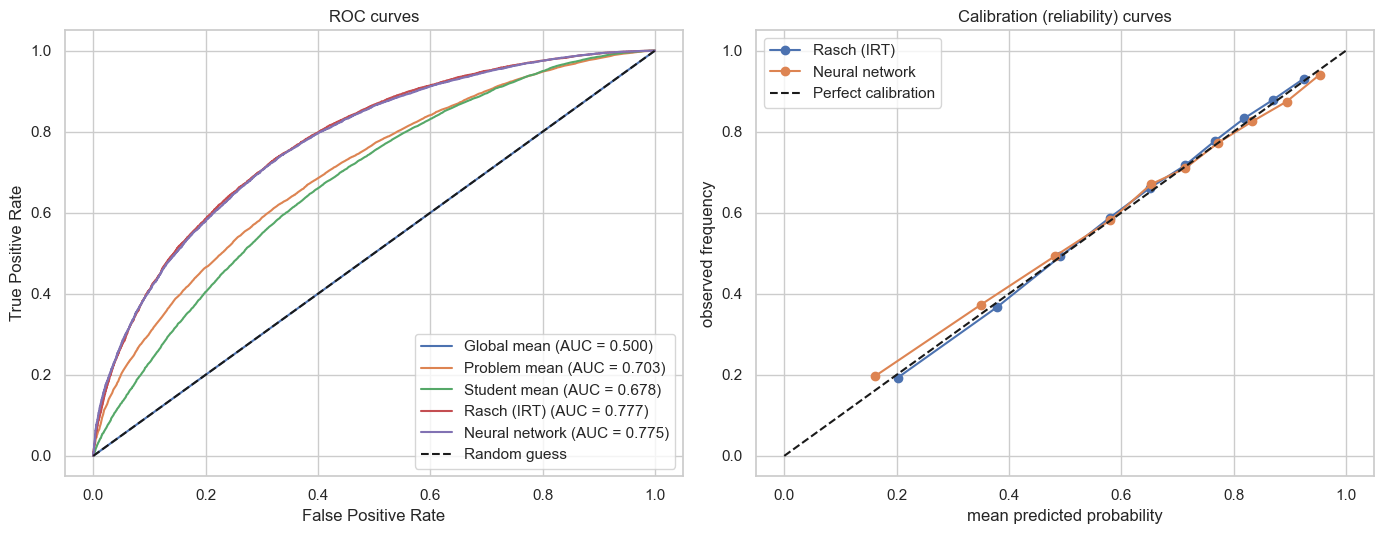

In [25]:
# ===================================================
# 10-3- ROC curves and calibration curves (منحنی ROC و منحنی کالیبراسیون)
# ===================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for name, probs in test_probs.items():
    fpr, tpr, _ = roc_curve(y_te, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_te, probs):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate"); axes[0].set_title("ROC curves")
axes[0].legend(loc="lower right")

for name in ["Rasch (IRT)", "Neural network"]:
    frac_pos, mean_pred = calibration_curve(y_te, test_probs[name], n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred, frac_pos, marker="o", label=name)
axes[1].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[1].set_xlabel("mean predicted probability"); axes[1].set_ylabel("observed frequency")
axes[1].set_title("Calibration (reliability) curves"); axes[1].legend()
plt.tight_layout()
plt.show()

### 10-4. Is the difference between the models statistically meaningful? (آیا تفاوت مدل ها معنادار است؟)
The test set is a single random sample, so the gap between two models may be just noise. We use a **paired bootstrap**: the test responses are resampled many times and both models are evaluated on exactly the same resample, so we get a confidence interval for the **difference** between them.

Two versions are computed:
- **Response-level bootstrap:** resamples individual responses (assumes responses are independent).
- **Student-level (cluster) bootstrap:** resamples whole students with all their test responses. Responses of the same student are correlated, so this version is more realistic and more conservative.

In both cases a **positive difference means that the Rasch model is better** (higher AUC, lower log-loss).

Response-level bootstrap done in 18 seconds
Student-level bootstrap done in 22 seconds


,Comparison (positive = Rasch better),Mean difference,95% CI low,95% CI high,Share of resamples Rasch better,CI excludes 0
0,Response-level bootstrap: AUC (Rasch - NN),0.0018,0.0001,0.0035,0.985,True
1,Response-level bootstrap: LogLoss (NN - Rasch),0.0021,0.0004,0.0037,0.995,True
2,Student-level bootstrap: AUC (Rasch - NN),0.0018,-0.0002,0.0036,0.960,False
3,Student-level bootstrap: LogLoss (NN - Rasch),0.0021,0.0002,0.0040,0.984,True


Rasch (IRT)     AUC 95% CI: [0.7704, 0.7829]   LogLoss 95% CI: [0.5269, 0.5390]
Neural network  AUC 95% CI: [0.7685, 0.7812]   LogLoss 95% CI: [0.5281, 0.5417]


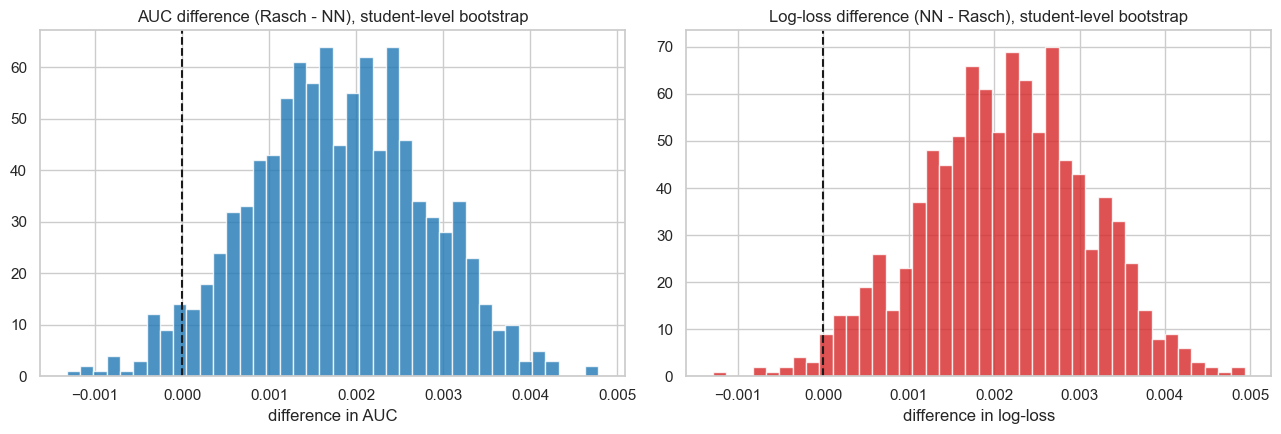

In [26]:
# ===================================================
# 10-4- Paired bootstrap for model comparison (بوت استرپ جفتی برای مقایسه مدل ها)
# ===================================================
def per_response_nll(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def paired_bootstrap(p_a, p_b, y, groups, n_boot=1000, by_group=True, seed=SEED):
    # Compare model A and model B on the same bootstrap resamples (مقایسه دو مدل روی نمونه های یکسان)
    # Resampling is implemented with integer weights: a response drawn k times gets weight k.
    # (نمونه برداری با وزن صحیح انجام می شود: پاسخی که k بار انتخاب شود وزن k می گیرد)
    r = np.random.default_rng(seed)
    nll_a, nll_b = per_response_nll(y, p_a), per_response_nll(y, p_b)
    unique_groups, g_index = np.unique(groups, return_inverse=True)
    out = {"auc_a": [], "auc_b": [], "ll_a": [], "ll_b": []}

    for _ in range(n_boot):
        if by_group:
            sampled = r.integers(0, len(unique_groups), len(unique_groups))
            w = np.bincount(sampled, minlength=len(unique_groups))[g_index].astype(float)
        else:
            w = np.bincount(r.integers(0, len(y), len(y)), minlength=len(y)).astype(float)
        out["auc_a"].append(roc_auc_score(y, p_a, sample_weight=w))
        out["auc_b"].append(roc_auc_score(y, p_b, sample_weight=w))
        out["ll_a"].append(np.average(nll_a, weights=w))
        out["ll_b"].append(np.average(nll_b, weights=w))
    return {k: np.array(v) for k, v in out.items()}


def summarize_difference(name, diff):
    lo, hi = np.percentile(diff, [2.5, 97.5])
    return {"Comparison (positive = Rasch better)": name, "Mean difference": diff.mean(),
            "95% CI low": lo, "95% CI high": hi,
            "Share of resamples Rasch better": np.mean(diff > 0),
            "CI excludes 0": bool(lo > 0 or hi < 0)}


boot_rows = []
boot_results = {}
for label, by_group in [("Response-level bootstrap", False), ("Student-level bootstrap", True)]:
    t0 = time.time()
    bt = paired_bootstrap(test_probs["Rasch (IRT)"], test_probs["Neural network"], y_te, u_te,
                          n_boot=1000, by_group=by_group)
    boot_results[label] = bt
    boot_rows.append({**summarize_difference(f"{label}: AUC (Rasch - NN)", bt["auc_a"] - bt["auc_b"])})
    boot_rows.append({**summarize_difference(f"{label}: LogLoss (NN - Rasch)", bt["ll_b"] - bt["ll_a"])})
    print(f"{label} done in {time.time() - t0:.0f} seconds")

boot_table = pd.DataFrame(boot_rows)
display(boot_table.round(4))

# Confidence intervals for each model alone (student-level) (فاصله اطمینان هر مدل به تنهایی)
bt = boot_results["Student-level bootstrap"]
for name, key_auc, key_ll in [("Rasch (IRT)", "auc_a", "ll_a"), ("Neural network", "auc_b", "ll_b")]:
    print(f"{name:15s} AUC 95% CI: [{np.percentile(bt[key_auc], 2.5):.4f}, {np.percentile(bt[key_auc], 97.5):.4f}]"
          f"   LogLoss 95% CI: [{np.percentile(bt[key_ll], 2.5):.4f}, {np.percentile(bt[key_ll], 97.5):.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(bt["auc_a"] - bt["auc_b"], bins=40, color="tab:blue", alpha=0.8)
axes[0].axvline(0, color="k", linestyle="--"); axes[0].set_title("AUC difference (Rasch - NN), student-level bootstrap")
axes[0].set_xlabel("difference in AUC")
axes[1].hist(bt["ll_b"] - bt["ll_a"], bins=40, color="tab:red", alpha=0.8)
axes[1].axvline(0, color="k", linestyle="--"); axes[1].set_title("Log-loss difference (NN - Rasch), student-level bootstrap")
axes[1].set_xlabel("difference in log-loss")
plt.tight_layout()
plt.show()

## 11. Error Analysis (تحلیل خطا)
Where does each model work better? We split the test responses by how many **training responses** the student has, and we check whether the neural network learns the **same ability and difficulty dimensions** as the Rasch model.

,Model,Train responses of student,n test,AUC,LogLoss
0,Rasch (IRT),<=15,2631,0.7750,0.5299
1,Rasch (IRT),16-30,2927,0.7595,0.5699
2,Rasch (IRT),31-60,4310,0.7681,0.5693
3,Rasch (IRT),>60,30875,0.7777,0.5241
4,Neural network,<=15,2631,0.7686,0.5315
5,Neural network,16-30,2927,0.7544,0.5782
6,Neural network,31-60,4310,0.7593,0.5806
7,Neural network,>60,30875,0.7774,0.5243


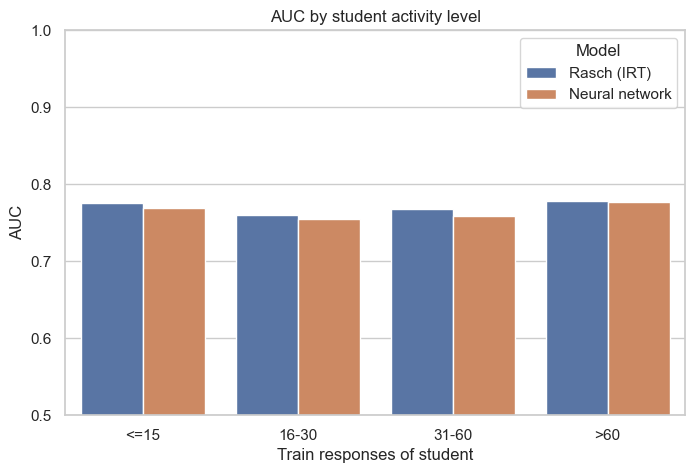

In [27]:
# ===================================================
# 11-1- Performance by student activity (عملکرد بر حسب میزان فعالیت دانش آموز)
# ===================================================
train_count_per_student = np.bincount(u_tr, minlength=n_users)
activity = pd.cut(train_count_per_student[u_te], bins=[0, 15, 30, 60, np.inf],
                  labels=["<=15", "16-30", "31-60", ">60"])

rows = []
for name in ["Rasch (IRT)", "Neural network"]:
    for level in activity.categories:
        mask = np.asarray(activity == level)
        if mask.sum() > 50 and len(np.unique(y_te[mask])) == 2:
            p = np.clip(test_probs[name][mask], 1e-6, 1 - 1e-6)
            rows.append({"Model": name, "Train responses of student": level, "n test": int(mask.sum()),
                         "AUC": roc_auc_score(y_te[mask], p), "LogLoss": log_loss(y_te[mask], p)})

by_activity = pd.DataFrame(rows)
display(by_activity.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=by_activity, x="Train responses of student", y="AUC", hue="Model")
plt.ylim(0.5, 1.0); plt.title("AUC by student activity level")
plt.show()

Spearman correlation: NN student score vs Rasch ability        = 0.967
Spearman correlation: NN problem easiness vs Rasch (-difficulty) = 0.971


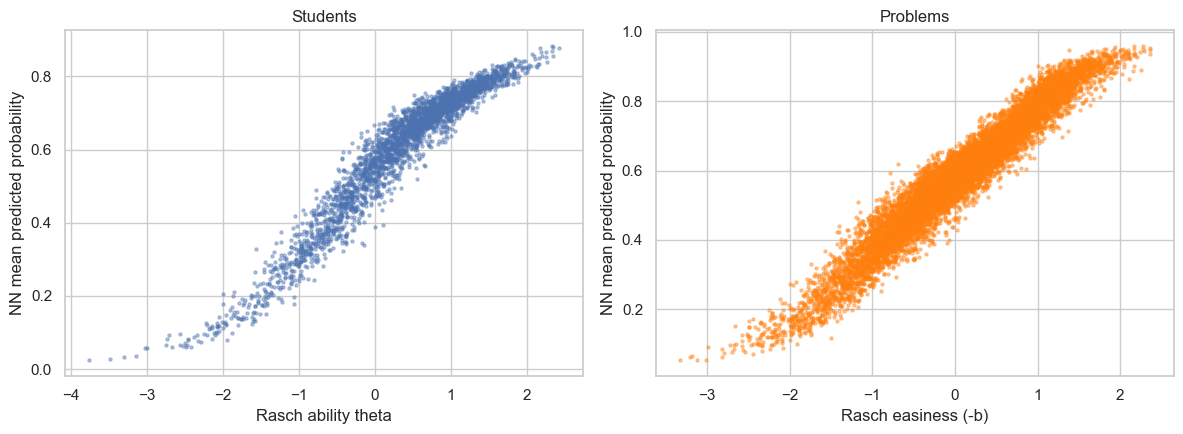

In [28]:
# ===================================================
# 11-2- Does the network learn the same ability/difficulty? (آیا شبکه همان توانایی و دشواری را یاد می گیرد؟)
# ===================================================
# Average predicted probability over a COMMON random set of problems (for students)
# and over a COMMON random set of students (for problems).
# (میانگین احتمال پیش بینی شده روی یک مجموعه مشترک از سوالات و دانش آموزان)
probe_items = rng.choice(n_items, size=min(300, n_items), replace=False)
probe_students = rng.choice(n_users, size=min(300, n_users), replace=False)

student_score = np.array([nn_predict(nn_params, np.full(len(probe_items), s), probe_items).mean() for s in range(n_users)])
problem_score = np.array([nn_predict(nn_params, probe_students, np.full(len(probe_students), q)).mean() for q in range(n_items)])

only_train_students = train_count_per_student > 0
corr_student = pd.Series(student_score[only_train_students]).corr(pd.Series(theta_hat[only_train_students]), method="spearman")
corr_problem = pd.Series(problem_score).corr(pd.Series(-b_hat), method="spearman")
print(f"Spearman correlation: NN student score vs Rasch ability        = {corr_student:.3f}")
print(f"Spearman correlation: NN problem easiness vs Rasch (-difficulty) = {corr_problem:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(theta_hat, student_score, s=5, alpha=0.4)
axes[0].set_xlabel("Rasch ability theta"); axes[0].set_ylabel("NN mean predicted probability"); axes[0].set_title("Students")
axes[1].scatter(-b_hat, problem_score, s=5, alpha=0.4, color="tab:orange")
axes[1].set_xlabel("Rasch easiness (-b)"); axes[1].set_ylabel("NN mean predicted probability"); axes[1].set_title("Problems")
plt.tight_layout()
plt.show()

## 12. Discussion and Limitations (بحث و محدودیت ها)

**Summary of findings (in our run; exact numbers are in the tables above):**
- Both models are far better than the simple baselines (AUC about 0.78 against about 0.70 for the best baseline). Problem difficulty is more informative than student ability alone.
- The Rasch model, with one parameter per student and one per problem, is slightly better than or equal to the neural network. The paired bootstrap (section 10-4, 1,000 resamples) shows a log-loss advantage of about 0.002 for the Rasch model whose 95% confidence interval excludes zero in both versions (student-level: [0.0002, 0.0040]). The AUC advantage is also about 0.002, but its student-level (more conservative) interval [-0.0002, 0.0036] includes zero. So the Rasch model is consistently but only marginally better in log-loss, and the two models are statistically indistinguishable in AUC; in practice the difference is negligible.
- Both models are well calibrated (ECE below 0.015); the network is slightly worse calibrated than the Rasch model.
- By student activity (section 11-1), the network is not better for any group: it is slightly worse for students with up to 60 training responses and equal for students with more than 60 (AUC 0.777 vs 0.777).
- The network learns essentially the same ability and difficulty dimensions as the Rasch model (Spearman correlations about 0.97, section 11-2). With about 25 responses per problem, the extra capacity of the network brings no gain, while the Rasch parameters stay directly interpretable.

**Limitations of this study:**
- **Non-random missing data.** In skill builder (mastery learning) problem sets, a student stops after answering 3 problems correctly in a row, so which problems a student sees depends on past performance. Both models ignore this selection effect.
- **Static ability.** IRT assumes a fixed ability per student; it does not model learning over time (Knowledge Tracing models such as BKT/DKT do).
- **No cold start.** Students and problems must appear in the training data; new students/problems are not handled.
- **Only first-attempt correctness** is modeled; hints, response time and skill structure are not used.
- A single random split is used; repeated splits or cross-validation would give confidence intervals.

**Possible extensions:** 2PL/3PL IRT models, using skill information, Deep Knowledge Tracing with an LSTM (PyTorch), temporal splits, and statistical tests for model comparison.

## 13. What this means for mathematics education (نتیجه‌گیری آموزشی)

1. **Which problem is asked matters as much as who answers it.** Knowing only a problem's average success rate predicts better (AUC 0.703) than knowing only a student's (0.678), and the two together are clearly best (0.777). A student's percentage correct can be misleading if we ignore how hard their problems were.
2. **A transparent measurement model is enough for this kind of data.** The Rasch model predicts first-attempt correctness as well as a neural network, and its two numbers (a difficulty for every problem, an ability for every student, on one shared scale) can be explained to teachers. A black box adds nothing here.
3. **The learnable structure is essentially one-dimensional in these data.** A flexible network recovered the same ability and difficulty scales (Spearman ≈ 0.97). This concerns right/wrong first attempts in these skill-builder sets; it does not mean that mathematical thinking itself is one-dimensional.
4. **Right/wrong data cannot explain *why*.** The models say nothing about strategies, representations or misconceptions behind an answer, or about whether the tutoring worked. Such questions need richer, process-level data, which is the natural next step: combining IRT-style measurement with information about how students solve problems.
